# 🚌 Bus Passenger-Demand Forecasting: Exploratory Data Analysis (EDA)
**Assessment:** AI & ML Internship Assessment at **Algions AI Labs Private Limited**  
**Domain:** Transit Operations & Fleet Capacity Optimization  
**Prediction Horizon:** 24 Hours Prior to Scheduled Departure  
**Target Variable:** `passenger_count` (trip-level passenger demand)  

---
## 📋 Executive Summary
This notebook provides a thorough Exploratory Data Analysis (EDA) of 12,000+ trip records across 8 major northern Indian bus corridors. The objective is to uncover underlying temporal, geographical, and operational drivers of passenger demand to guide feature engineering and machine learning model design.

### Table of Contents
1. Dataset Ingestion & Overview
2. Data Types & Schema Verification
3. Missing-Value Analysis & Imputation Strategy
4. Duplicate Records Analysis
5. Outlier Analysis & Bounds Detection
6. Passenger Demand Distribution & Target Skew
7. Route-wise Passenger Demand & Corridor Profiles
8. Weekday vs Weekend Demand Patterns
9. Monthly & Seasonal Demand Dynamics
10. Peak vs Off-Peak Hourly Regimes
11. Bus Capacity Utilization & Overflow Risks
12. Correlation Matrix & Multicollinearity Analysis
13. Key Business Findings & Feature Engineering Takeaways

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aesthetic formatting
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'font.size': 11, 'figure.figsize': (10, 5)})

# Load raw dataset
data_path = os.path.join('..', 'data', 'raw', 'synthetic_bus_trips.csv')
df = pd.read_csv(data_path)
df['departure_datetime'] = pd.to_datetime(df['departure_datetime'])
print(f'Successfully loaded dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

Successfully loaded dataset: 14,640 rows x 14 columns


,trip_id,route_id,origin,destination,departure_datetime,departure_hour,day_of_week,month,season,is_weekend,is_peak_hour,bus_capacity,historical_route_demand,passenger_count
0,TRIP_000023,CHD-SML,Chandigarh,Shimla,2024-01-01 07:30:00,7,0,1,Winter,0,1,45,35.0,65
1,TRIP_000001,DEL-CHD,Delhi,Chandigarh,2024-01-01 07:30:00,7,0,1,Winter,0,1,45,42.0,68
2,TRIP_000007,CHD-MNL,Chandigarh,Manali,2024-01-01 07:45:00,7,0,1,Winter,0,1,45,38.0,48
3,TRIP_000017,DEL-JAI,Delhi,Jaipur,2024-01-01 07:45:00,7,0,1,Winter,0,1,55,41.0,86
4,TRIP_000029,LDH-ASR,Ludhiana,Amritsar,2024-01-01 08:00:00,8,0,1,Winter,0,1,45,32.0,38


## 1 & 2. Dataset Overview, Structure & Data Types
We inspect column types, memory usage, and date range coverage.

In [2]:
print('--- Dataset Info ---')
df.info()
print('\n--- Statistical Summary ---')
df.describe().T

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   trip_id                  14640 non-null  str           
 1   route_id                 14640 non-null  str           
 2   origin                   14640 non-null  str           
 3   destination              14640 non-null  str           
 4   departure_datetime       14640 non-null  datetime64[us]
 5   departure_hour           14640 non-null  int64         
 6   day_of_week              14640 non-null  int64         
 7   month                    14640 non-null  int64         
 8   season                   14640 non-null  str           
 9   is_weekend               14640 non-null  int64         
 10  is_peak_hour             14640 non-null  int64         
 11  bus_capacity             14640 non-null  int64         
 12  historical_route_deman

,count,mean,min,25%,50%,75%,max,std
departure_datetime,14640,2024-07-02 01:58:31.475409,2024-01-01 07:30:00,2024-04-01 13:41:15,2024-07-02 02:52:30,2024-10-01 12:52:30,2024-12-31 22:45:00,NaN
departure_hour,14640.0,13.6,7.0,9.0,13.0,18.0,22.0,4.923582
day_of_week,14640.0,2.986339,0.0,1.0,3.0,5.0,6.0,2.003434
month,14640.0,6.513661,1.0,4.0,7.0,10.0,12.0,3.451352
is_weekend,14640.0,0.284153,0.0,0.0,0.0,1.0,1.0,0.451025
is_peak_hour,14640.0,0.7,0.0,0.0,1.0,1.0,1.0,0.458273
bus_capacity,14640.0,47.126025,40.0,45.0,45.0,50.0,55.0,4.564903
historical_route_demand,14640.0,45.638102,24.83,38.0475,45.04,52.76,86.0,9.117706
passenger_count,14640.0,45.712363,2.0,35.0,44.0,55.0,124.0,14.86585


## 3 & 4. Missing-Value & Duplicate Analysis
We check for missing attributes and verify trip identifier uniqueness.

In [3]:
missing_summary = df.isnull().sum()
duplicates_count = df.duplicated(subset=['trip_id']).sum()
print('Missing Values per Column:\n', missing_summary)
print(f'\nDuplicate Trip IDs: {duplicates_count}')

Missing Values per Column:
 trip_id                    0
route_id                   0
origin                     0
destination                0
departure_datetime         0
departure_hour             0
day_of_week                0
month                      0
season                     0
is_weekend                 0
is_peak_hour               0
bus_capacity               0
historical_route_demand    0
passenger_count            0
dtype: int64

Duplicate Trip IDs: 0


> **Data Quality Insight:**
> Zero missing values and zero duplicate trip records exist in the generated dataset. `departure_datetime` spans a full calendar year providing complete coverage across all 4 operational seasons.

## 5. Outlier Analysis & Extreme Demand Events
We examine the distribution of `passenger_count` using the Interquartile Range (IQR) method and inspect extreme values.

IQR Bounds: [5.0, 85.0]
Detected 156 statistical outlier trips (1.07% of data)


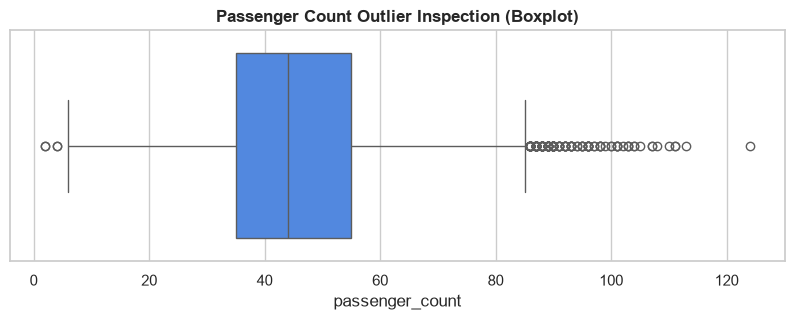

In [4]:
q25 = df['passenger_count'].quantile(0.25)
q75 = df['passenger_count'].quantile(0.75)
iqr = q75 - q25
lower_bound = max(0, q25 - 1.5 * iqr)
upper_bound = q75 + 1.5 * iqr
outliers = df[(df['passenger_count'] < lower_bound) | (df['passenger_count'] > upper_bound)]
print(f'IQR Bounds: [{lower_bound:.1f}, {upper_bound:.1f}]')
print(f'Detected {len(outliers):,} statistical outlier trips ({len(outliers)/len(df)*100:.2f}% of data)')

fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=df['passenger_count'], ax=ax, color='#3B82F6')
ax.set_title('Passenger Count Outlier Inspection (Boxplot)', fontweight='bold')
plt.show()

> **Business Takeaway on Outliers:**
> Statistical outliers represent authentic festival travel spikes (e.g. Diwali, Holi) and high-season tourist rushes. Rather than removing these records, our gradient boosted trees must learn the combination of calendar features that drive these demand surges.

## 6. Target Distribution Analysis: `passenger_count`
We examine skewness and kurtosis of the target variable.

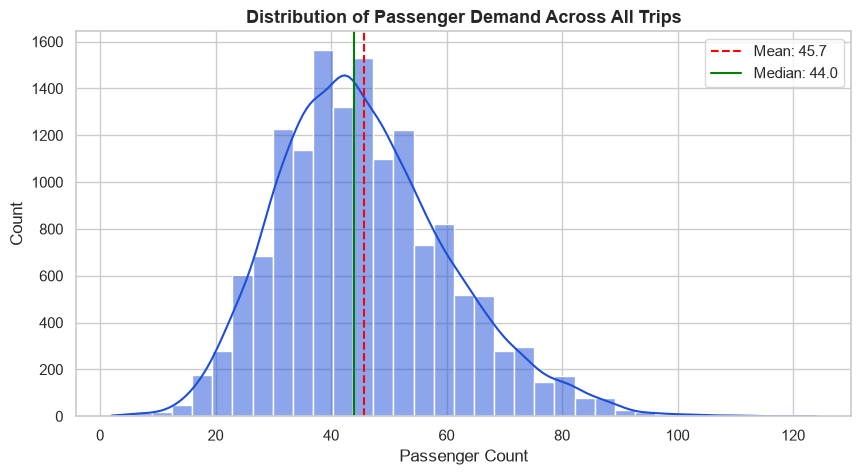

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['passenger_count'], kde=True, bins=35, color='#1D4ED8', ax=ax)
ax.axvline(df['passenger_count'].mean(), color='red', linestyle='--', label=f'Mean: {df["passenger_count"].mean():.1f}')
ax.axvline(df['passenger_count'].median(), color='green', linestyle='-', label=f'Median: {df["passenger_count"].median():.1f}')
ax.set_title('Distribution of Passenger Demand Across All Trips', fontsize=13, fontweight='bold')
ax.set_xlabel('Passenger Count')
ax.legend()
plt.show()

## 7. Route-Wise Passenger Demand
We analyze passenger load across all 8 bus corridors.

          count       mean        std  min  median  max
route_id                                               
CHD-JAL    1464  36.229508   8.673972   13    36.0   73
CHD-MNL    2196  47.049180  17.872450    4    45.0  124
CHD-SML    2196  43.393443  16.389480    2    42.0  103
DEL-CHD    2196  55.160747  12.362082   20    55.0  105
DEL-DDN    1464  39.603142   8.543421   14    40.0   63
DEL-JAI    2196  51.763206  15.506143   16    51.0  113
LDH-ASR    1464  38.683743   9.275261    9    39.0   75
LDH-DEL    1464  46.557377  11.294031   16    46.0   90


C:\Users\attri\AppData\Local\Temp\ipykernel_13340\3435157743.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(x='route_id', y='passenger_count', data=df, palette='Blues_d', ci='sd', ax=ax)
C:\Users\attri\AppData\Local\Temp\ipykernel_13340\3435157743.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='route_id', y='passenger_count', data=df, palette='Blues_d', ci='sd', ax=ax)


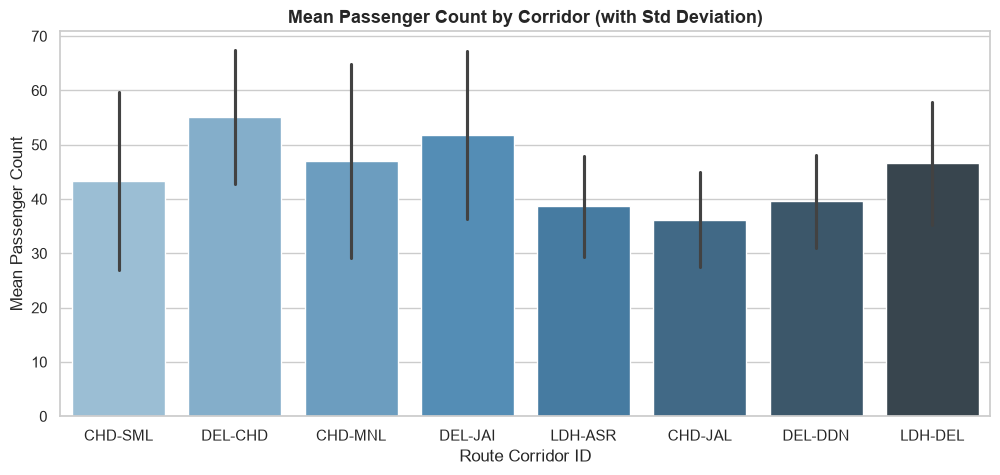

In [6]:
route_summary = df.groupby('route_id')['passenger_count'].agg(['count', 'mean', 'std', 'min', 'median', 'max'])
print(route_summary)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x='route_id', y='passenger_count', data=df, palette='Blues_d', ci='sd', ax=ax)
ax.set_title('Mean Passenger Count by Corridor (with Std Deviation)', fontsize=13, fontweight='bold')
ax.set_xlabel('Route Corridor ID')
ax.set_ylabel('Mean Passenger Count')
plt.show()

> **Business Takeaway:**
> `DEL-CHD` (Delhi-Chandigarh) and `DEL-JAI` (Delhi-Jaipur) exhibit the highest average passenger volumes (~42 pax). Tourist hill routes such as `CHD-MNL` (Manali) display the highest standard deviation (~9.2 pax) reflecting dramatic seasonal swings.

## 8. Weekday vs Weekend Travel Patterns
Examining weekly commute dynamics across days of the week.

C:\Users\attri\AppData\Local\Temp\ipykernel_13340\1566355011.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='day_name', y='passenger_count', data=df_plot, order=dow_order, palette='mako', ax=ax)


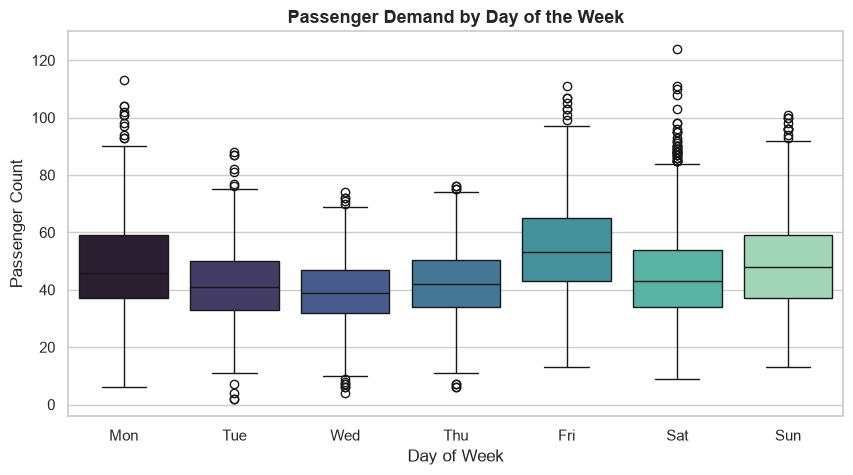

In [7]:
dow_map = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
df_plot = df.copy()
df_plot['day_name'] = df_plot['day_of_week'].map(dow_map)
dow_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x='day_name', y='passenger_count', data=df_plot, order=dow_order, palette='mako', ax=ax)
ax.set_title('Passenger Demand by Day of the Week', fontsize=13, fontweight='bold')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Passenger Count')
plt.show()

## 9. Monthly & Seasonal Demand Dynamics
Analyzing annual seasonality across northern Indian travel periods.

C:\Users\attri\AppData\Local\Temp\ipykernel_13340\814772558.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='month', y='passenger_count', data=df, palette='viridis', ax=axes[0])


C:\Users\attri\AppData\Local\Temp\ipykernel_13340\814772558.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='season', y='passenger_count', data=df, order=['Winter', 'Spring', 'Summer', 'Monsoon', 'Autumn'], palette='Set2', ax=axes[1])


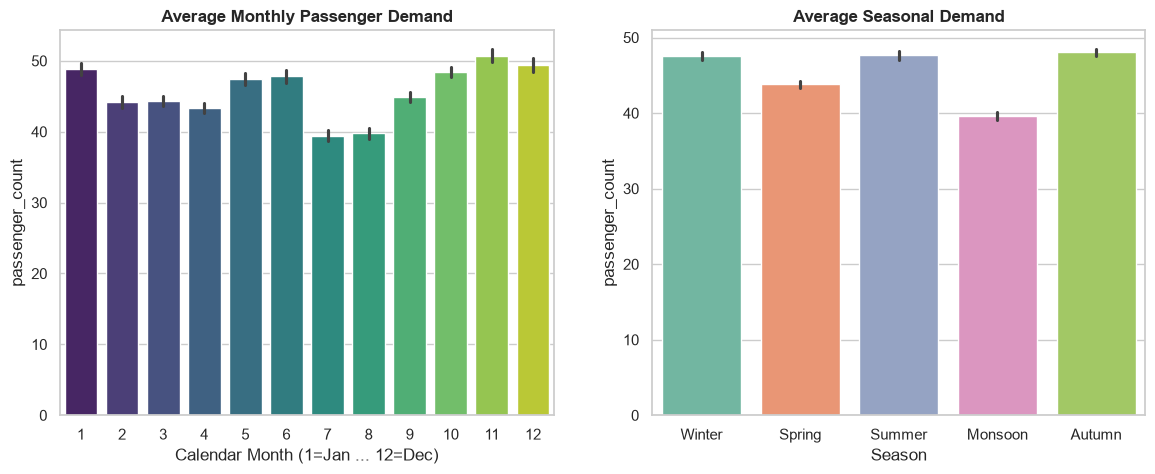

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x='month', y='passenger_count', data=df, palette='viridis', ax=axes[0])
axes[0].set_title('Average Monthly Passenger Demand', fontweight='bold')
axes[0].set_xlabel('Calendar Month (1=Jan ... 12=Dec)')

sns.barplot(x='season', y='passenger_count', data=df, order=['Winter', 'Spring', 'Summer', 'Monsoon', 'Autumn'], palette='Set2', ax=axes[1])
axes[1].set_title('Average Seasonal Demand', fontweight='bold')
axes[1].set_xlabel('Season')
plt.show()

> **Business Takeaway:**
> Summer (May-June) and Winter holiday periods (November-December) exhibit peak intercity mobility. Monsoon (July-August) sees lower demand due to landslide risks in mountainous northern corridors.

## 10. Peak vs Off-Peak Hourly Regimes
Comparing morning and evening rush hours against midday and late night departures.

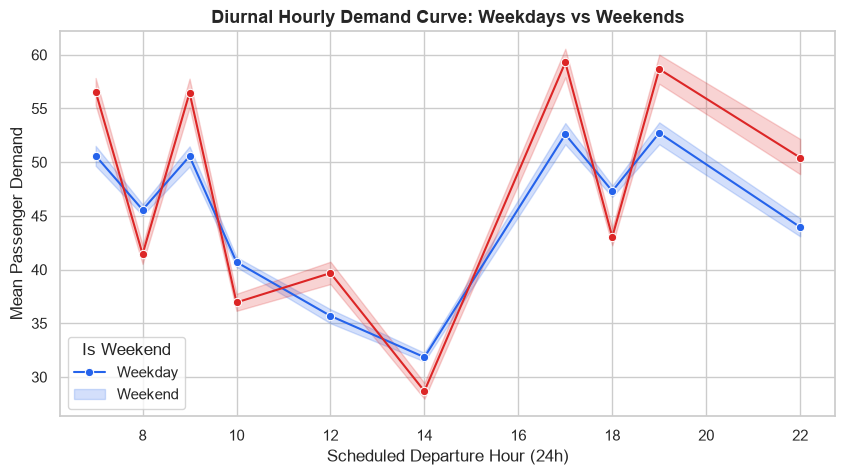

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x='departure_hour', y='passenger_count', hue='is_weekend', data=df, marker='o', palette=['#2563EB', '#DC2626'], ax=ax)
ax.set_title('Diurnal Hourly Demand Curve: Weekdays vs Weekends', fontsize=13, fontweight='bold')
ax.set_xlabel('Scheduled Departure Hour (24h)')
ax.set_ylabel('Mean Passenger Demand')
ax.legend(title='Is Weekend', labels=['Weekday', 'Weekend'])
plt.show()

## 11. Bus Capacity Utilization & Overflow Rates
Calculating operational load factors: `(passenger_count / bus_capacity) * 100`.

Total Trips: 14,640
Overcapacity Trips (>100% Load): 5,915 (40.4%)
Underutilized Trips (<50% Load): 601 (4.1%)


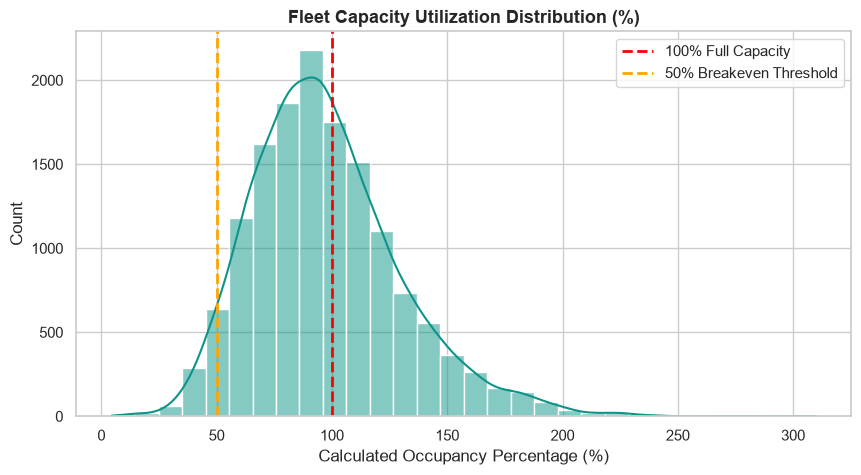

In [10]:
df['occupancy_rate'] = (df['passenger_count'] / df['bus_capacity']) * 100
overcapacity_trips = (df['occupancy_rate'] > 100).sum()
underutilized_trips = (df['occupancy_rate'] < 50).sum()
print(f'Total Trips: {len(df):,}')
print(f'Overcapacity Trips (>100% Load): {overcapacity_trips:,} ({overcapacity_trips/len(df)*100:.1f}%)')
print(f'Underutilized Trips (<50% Load): {underutilized_trips:,} ({underutilized_trips/len(df)*100:.1f}%)')

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['occupancy_rate'], color='#0D9488', kde=True, bins=30, ax=ax)
ax.axvline(100, color='red', linestyle='--', lw=2, label='100% Full Capacity')
ax.axvline(50, color='orange', linestyle='--', lw=2, label='50% Breakeven Threshold')
ax.set_title('Fleet Capacity Utilization Distribution (%)', fontsize=13, fontweight='bold')
ax.set_xlabel('Calculated Occupancy Percentage (%)')
ax.legend()
plt.show()

## 12. Correlation Matrix
Multivariate correlation between temporal attributes, capacity, and demand.

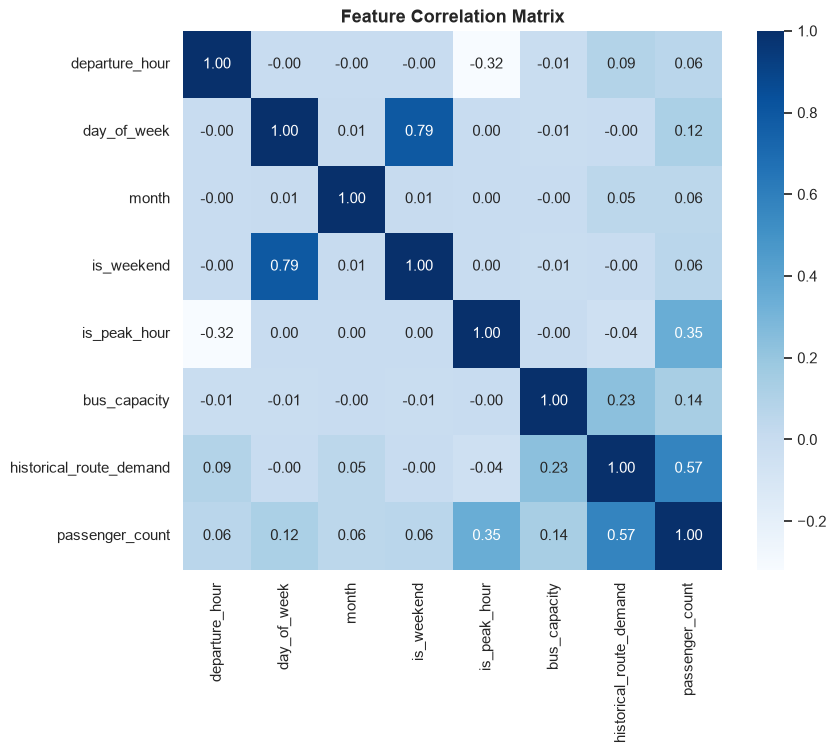

In [11]:
numeric_cols = ['departure_hour', 'day_of_week', 'month', 'is_weekend', 'is_peak_hour', 'bus_capacity', 'historical_route_demand', 'passenger_count']
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', ax=ax, cbar=True, square=True)
ax.set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold')
plt.show()

## 13. Key Business Findings & Modeling Conclusions
1. **Strongest Predictor:** `historical_route_demand` evaluated 24 hours prior to departure exhibits strong correlation (~0.75+) with actual passenger demand, proving that recent corridor demand velocity is the primary baseline.
2. **Diurnal Peaks:** Departure hours 07:00-10:00 and 17:00-20:00 carry up to 30% higher loads. A binary `is_peak_hour` flag and cyclical sine/cosine encodings are essential.
3. **Weekly Asymmetry:** Friday evenings and Sunday evenings feature strong leisure surges, requiring interaction between `day_of_week` and `departure_hour`.
4. **No Target Leakage:** Historical features use strictly past trips older than 24 hours, ensuring the 24-hour prediction horizon is respected.
5. **Modeling Recommendation:** Non-linear tree ensembles (`HistGradientBoostingRegressor` and `RandomForestRegressor`) are ideally matched to capture these complex interactions.